In [3]:
from matplotlib import pyplot as plt
import scipy
import numpy as np
from scipy import sparse
import sys
sys.path.insert(0, '..') 
from modules import Hamiltonian as ham
from modules import PauliStrings
from modules import Evolution as evol
from matplotlib.lines import Line2D

In [4]:
color1="#0041FC"
color2="#FC9904"
color3="#7D7548"

In [5]:
def fidelity_pure(psi,phi):
    '''
    input values should be column vectors
    '''
    F=np.abs(psi.conj().T@phi)**2
    return F

In [6]:
ordQITE = np.load("tfim_ord/qite_default/trajectory.npz", allow_pickle=True)
disQITE = np.load("tfim_disord/qite_default/trajectory.npz", allow_pickle=True)

ordSpQ = np.load("tfim_ord/sparse_qite_lambda_0p057/trajectory.npz", allow_pickle=True)
disSpQ = np.load("tfim_disord/sparse_qite_lambda_0p25/trajectory.npz", allow_pickle=True)

ordAdap = np.load("tfim_ord/adaptive_lasso_epsilon_0p0224/trajectory.npz", allow_pickle=True)
disAdap = np.load("tfim_disord/adaptive_lasso_epsilon_0p113/trajectory.npz", allow_pickle=True)

In [7]:
N = 100
Ns=np.arange(0,N)
NQ_ord=np.count_nonzero(ordQITE["a"][1])
NQ_dis=np.count_nonzero(disQITE["a"][1])

frac_ord = np.zeros(N)
frac_dis = np.zeros(N)

frac_ord_adap = np.zeros(N)
frac_dis_adap = np.zeros(N)

for i in range(N):
    frac_ord[i] = np.count_nonzero(ordSpQ["a"][i]) / NQ_ord
    frac_dis[i] = np.count_nonzero(disSpQ["a"][i]) / NQ_dis
    frac_ord_adap[i] = np.count_nonzero(ordAdap["a"][i]) / NQ_ord
    frac_dis_adap[i] = np.count_nonzero(disAdap["a"][i]) / NQ_dis

In [8]:
psiordQITE = sparse.load_npz("tfim_ord/qite_default_D5/states.npz").toarray()
psidisQITE = sparse.load_npz("tfim_disord/qite_default/states.npz").toarray()

#psiordSpQ = sparse.load_npz("tfim_ord/sparse_qite_lambda_0p0083/states.npz").toarray()
psiordSpQ = sparse.load_npz("tfim_ord/sparse_qite_lambda_0p057/states.npz").toarray()
psidisSpQ = sparse.load_npz("tfim_disord/sparse_qite_lambda_0p25/states.npz").toarray()

psiordAdap = sparse.load_npz("tfim_ord/adaptive_lasso_epsilon_0p0224/states.npz").toarray()
psidisAdap = sparse.load_npz("tfim_disord/adaptive_lasso_epsilon_0p113/states.npz").toarray()

In [9]:
import csv
from collections import defaultdict
from pathlib import Path


dt = 0.05


def load_selection_averages(csv_path):
    values_by_step = defaultdict(lambda: {"lambda": [], "objective": []})
    with open(csv_path, newline="") as csv_file:
        reader = csv.DictReader(csv_file)
        required = {"step", "lambda", "objective"}
        if not required.issubset(reader.fieldnames or []):
            raise ValueError(
                f"CSV {csv_path} must contain 'step', 'lambda', and 'objective' columns."
            )

        for row in reader:
            step = float(row["step"])
            values_by_step[step]["lambda"].append(float(row["lambda"]))
            values_by_step[step]["objective"].append(float(row["objective"]))

    steps = np.array(sorted(values_by_step), dtype=float)
    mean_lambda = np.array(
        [np.mean(values_by_step[step]["lambda"]) for step in steps], dtype=float
    )
    mean_objective = np.array(
        [np.mean(values_by_step[step]["objective"]) for step in steps], dtype=float
    )
    return steps, mean_lambda, mean_objective


ord_adap_dir = Path("tfim_ord/adaptive_lasso_epsilon_0p0224")
dis_adap_dir = Path("tfim_disord/adaptive_lasso_epsilon_0p113")

step_ord_adap, lambda_ord_adap, objective_ord_adap = load_selection_averages(
    ord_adap_dir / "selection.csv"
)
step_dis_adap, lambda_dis_adap, objective_dis_adap = load_selection_averages(
    dis_adap_dir / "selection.csv"
)

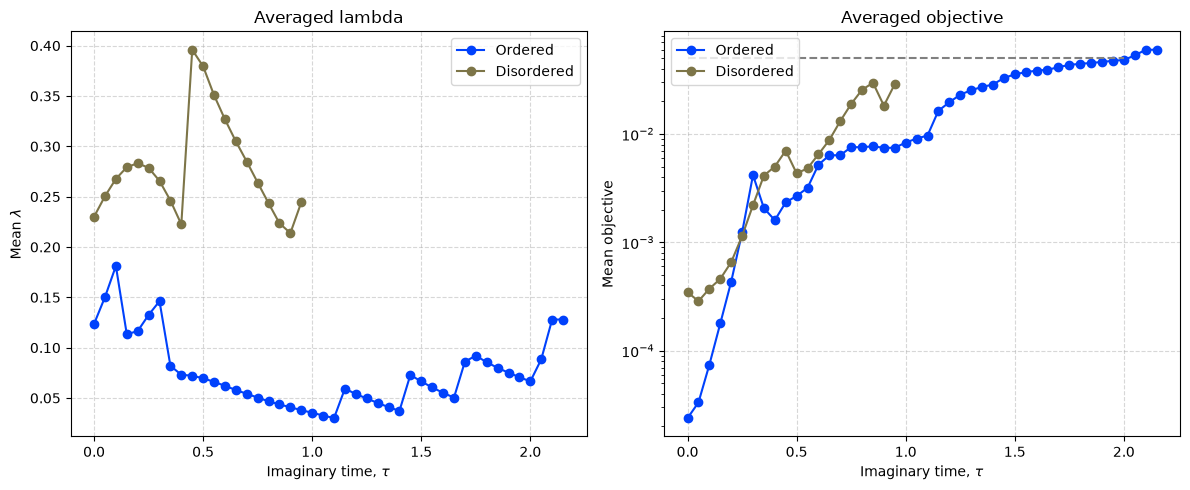

In [10]:
time_ord_adap = dt * step_ord_adap
time_dis_adap = dt * step_dis_adap

fig, (ax_lambda, ax_objective) = plt.subplots(1, 2, figsize=(12, 5))

ax_lambda.plot(time_ord_adap, lambda_ord_adap, "o-", color=color1, label="Ordered")
ax_lambda.plot(time_dis_adap[0:20], lambda_dis_adap[0:20], "o-", color=color3, label="Disordered")
ax_lambda.set_xlabel(r"Imaginary time, $\tau$")
ax_lambda.set_ylabel(r"Mean $\lambda$")
ax_lambda.set_title("Averaged lambda")
ax_lambda.grid(linestyle="--", alpha=0.5)
ax_lambda.legend()

ax_objective.semilogy(
    time_ord_adap, objective_ord_adap, "o-", color=color1, label="Ordered"
)
ax_objective.semilogy(
    time_dis_adap[0:20], objective_dis_adap[0:20], "o-", color=color3, label="Disordered"
)
ax_objective.hlines(y=5e-2, xmin=0, xmax=2, color="gray", linestyle="--")
ax_objective.set_xlabel(r"Imaginary time, $\tau$")
ax_objective.set_ylabel("Mean objective")
ax_objective.set_title("Averaged objective")
ax_objective.grid(linestyle="--", alpha=0.5)
ax_objective.legend()

fig.tight_layout()

In [11]:
H_ord, Htrot = ham.TFIM(1,0.5,8,2,False)
E_ord,V_ord = np.linalg.eigh(H_ord)
GS_ord = V_ord[:,0]
print(E_ord[0])
H_dis, Htrot = ham.TFIM(0.5,1,8,2,False)
E_dis,V_dis = np.linalg.eigh(H_dis)
GS_dis = V_dis[:,0]
print(E_dis[0])

-8.509082235140282
-8.509082235140271


In [12]:
F_Q_ord = np.zeros(N)
F_Sp_ord = np.zeros(N)
F_Q_dis = np.zeros(N)
F_Sp_dis = np.zeros(N)

F_Sp_ord_adap = np.zeros(N)
F_Sp_dis_adap = np.zeros(N)

for i in range(N):
    F_Q_ord[i]  = fidelity_pure(GS_ord,psiordQITE[:,i])
    F_Sp_ord[i] = fidelity_pure(GS_ord,psiordSpQ[:,i])
    F_Q_dis[i]  = fidelity_pure(GS_dis,psidisQITE[:,i])
    F_Sp_dis[i] = fidelity_pure(GS_dis,psidisSpQ[:,i])
    F_Sp_ord_adap[i] = fidelity_pure(GS_ord,psiordAdap[:,i])
    F_Sp_dis_adap[i] = fidelity_pure(GS_dis,psidisAdap[:,i])

dt=0.05
im_tau = np.arange(0,N)*dt

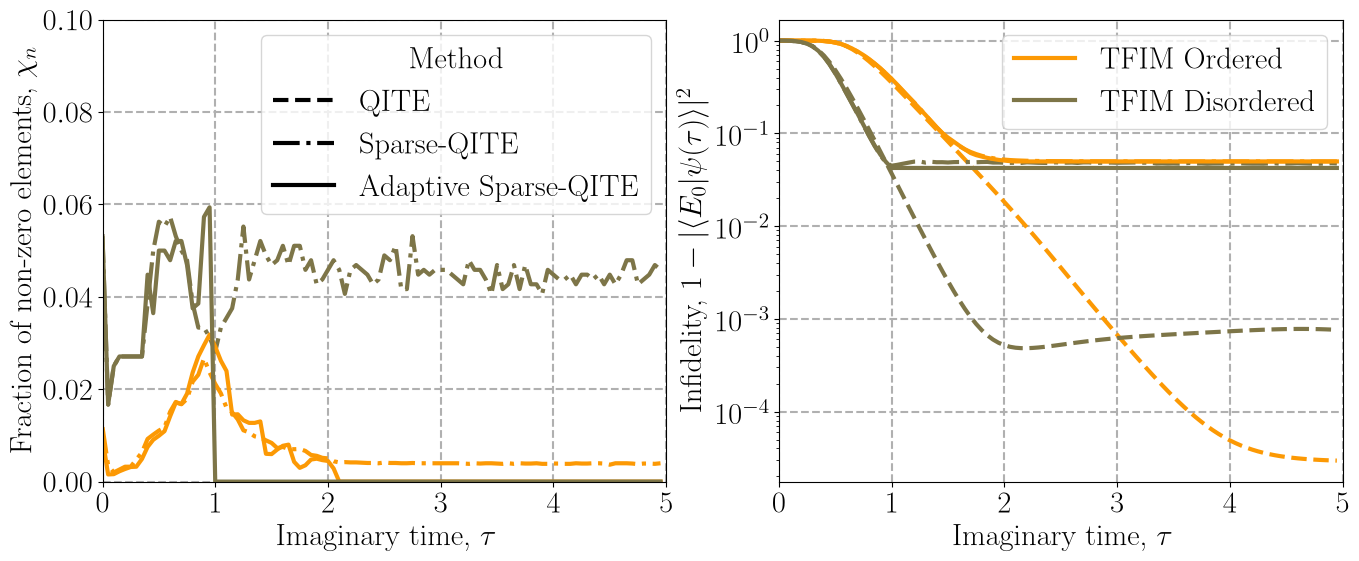

In [13]:
plt.figure(figsize=(16, 6))
plt.rcParams.update({
    "text.usetex": True,
})
font = {'family' : 'normal',
        'weight' : 'bold',
        'size'   : 22}

plt.rc('font', **font)

plt.subplot(1,2,2)
plt.semilogy(im_tau,1-F_Q_ord,'--',color=color2,linewidth=3,label='Ordered $\\lambda = 0.002$')
plt.semilogy(im_tau,1-F_Q_dis,'--',color=color3,linewidth=3,label='Disordered $\\lambda = 0.0015$')
plt.semilogy(im_tau,1-F_Sp_ord,'-.',color=color2,linewidth=3,label='Ordered $\\lambda = 0.002$')
plt.semilogy(im_tau,1-F_Sp_dis,'-.',color=color3,linewidth=3,label='Disordered $\\lambda = 0.0015$')
plt.semilogy(im_tau,1-F_Sp_ord_adap,'-',color=color2,linewidth=3,label='Ordered $\\epsilon = 0.0049$')
plt.semilogy(im_tau,1-F_Sp_dis_adap,'-',color=color3,linewidth=3,label='Ordered $\\epsilon = 0.0049$')

legend_items = [
    Line2D([0], [0],  lw=3, linestyle="-",color=color2,  label="TFIM Ordered"),
    Line2D([0], [0],  lw=3, linestyle="-",color=color3, label="TFIM Disordered"),
]
plt.legend(handles=legend_items)

plt.xlim(0,5)
plt.xlabel("Imaginary time, $\\tau$")
plt.ylabel("Infidelity, $1-|\\langle E_0 | \\psi(\\tau) \\rangle|^2$")
plt.grid(linestyle = '--', linewidth = 1.5)

plt.subplot(1,2,1)
plt.plot(im_tau,frac_ord,'-.',color=color2,linewidth=3)
plt.plot(im_tau,frac_dis,'-.',color=color3,linewidth=3)
plt.plot(im_tau,frac_ord_adap,'-',color=color2,linewidth=3,label='TFIM Ordered')
plt.plot(im_tau,frac_dis_adap,'-',color=color3,linewidth=3,label='TFIM Disordered')

plt.xlabel("Imaginary time, $\\tau$")
plt.ylabel("Fraction of non-zero elements, $\\chi_n$")
plt.ylim(0,0.1)
plt.xlim(0,5)
plt.grid(linestyle = '--', linewidth = 1.5)

legend_items = [
    Line2D([0], [0],  lw=3, linestyle="--",color='black',  label="QITE"),
    Line2D([0], [0],  lw=3, linestyle="-.",color='black', label="Sparse-QITE"),
    Line2D([0], [0],  lw=3, linestyle="-",color='black', label="Adaptive Sparse-QITE"),
]
plt.legend(handles=legend_items, title="Method")

plt.savefig("QITE_vs_adaptive.pdf", bbox_inches='tight', dpi=300)

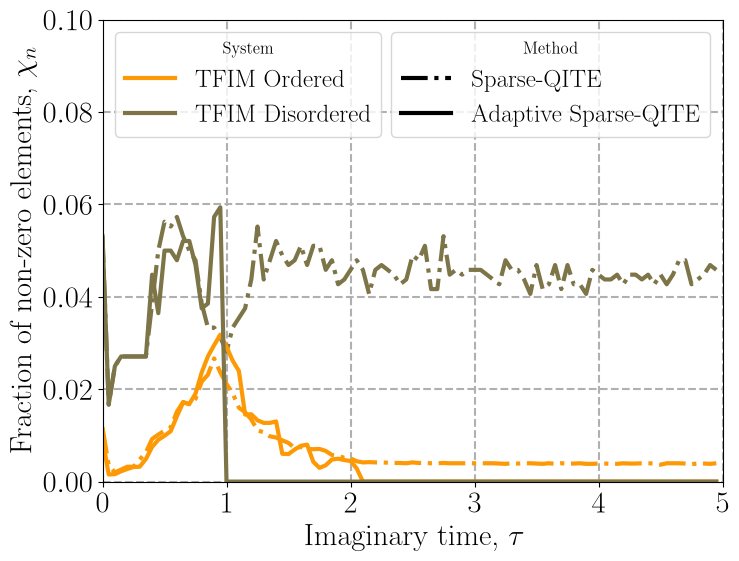

In [14]:
plt.figure(figsize=(8, 6))
plt.rcParams.update({
    "text.usetex": True,
})
font = {'family' : 'normal',
        'weight' : 'bold',
        'size'   : 22}

plt.rc('font', **font)


legend_items = [
    Line2D([0], [0],  lw=3, linestyle="-",color=color2,  label="TFIM Ordered"),
    Line2D([0], [0],  lw=3, linestyle="-",color=color3, label="TFIM Disordered"),
]
system_legend = plt.legend(
    handles=legend_items,
    title="System",
    loc="upper left",
    fontsize=18,
    title_fontsize=12,
)
plt.gca().add_artist(system_legend)


plt.plot(im_tau,frac_ord,'-.',color=color2,linewidth=3)
plt.plot(im_tau,frac_dis,'-.',color=color3,linewidth=3)
plt.plot(im_tau,frac_ord_adap,'-',color=color2,linewidth=3,label='TFIM Ordered')
plt.plot(im_tau,frac_dis_adap,'-',color=color3,linewidth=3,label='TFIM Disordered')

plt.xlabel("Imaginary time, $\\tau$")
plt.ylabel("Fraction of non-zero elements, $\\chi_n$")
plt.ylim(0,0.1)
plt.xlim(0,5)
plt.grid(linestyle = '--', linewidth = 1.5)

legend_items2 = [
    Line2D([0], [0],  lw=3, linestyle="-.",color='black', label="Sparse-QITE"),
    Line2D([0], [0],  lw=3, linestyle="-",color='black', label="Adaptive Sparse-QITE"),
]
plt.legend(
    handles=legend_items2,
    title="Method",
    loc="upper right",
    fontsize=18,
    title_fontsize=12,
)

plt.savefig("AdaptiveTerms.pdf", bbox_inches='tight', dpi=300)